# Goal

Often, you'll work with data from a new survey and/or telescope, and want to create pretty colour images. You've decided on your weight dictionary (i.e., mapping bands to rgb channels) and the scale function (e.g., asinh). However, these new images have a different depth and perhaps the goal is the images is different too (e.g., visualizing the fainter regions vs the bright cores of galaxies). How do you then go about finetuning the asinh parameters? This is more art than science, but below I'll go through one possible workflow that I've used in the past.

# Imports

In [1]:
import sys
sys.path.append("..") #Point this to where the ensor.py file is located
from ensor import *

# Code

### Part 0: Loading image

Let's image you were given Rubin-like images, and want to create colour images from them. Let's start with opening the Rubin-like image. These images were in njy, so we first convert them to nanomaggies.

In [2]:
#Opening a fits file with gri bands. 
images_dir = '../data/'
fileloc = f'{images_dir}/Rubin/example13.fits'

hdul = fits.open(fileloc)

g = njy_to_nanomaggy(hdul[1].data) #convert to nanomaggies
r = njy_to_nanomaggy(hdul[2].data)
i = njy_to_nanomaggy(hdul[3].data)

### Part 1: Check out old scaling 

A good starting point is to copy the weights dictionary and the scaling/stretch function of an existing survey that you like. In this case, we'll use the Legacy/SDSS weights and scaling (i.e., asinh). You can start with the values of the scaling parameters, and update them as you like for your new images.


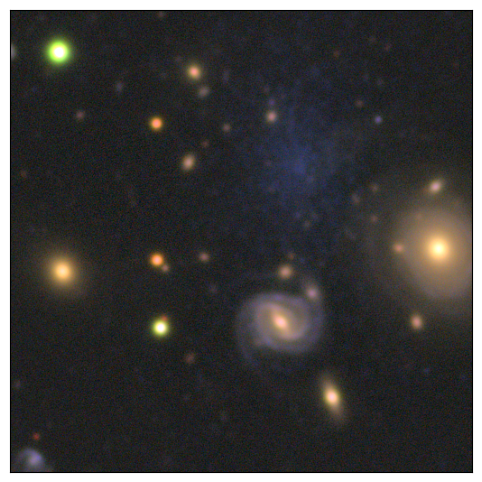

In [3]:
imgs = [g,r,i]
bands = ['g','r','i']

weights = dict( #Legacy/SDSS image scaling
    g = (0, 0, 6.0),  # r, g, b
    r = (0, 3.4, 0.),
    i = (3.0,0, 0),
    )

Q = 20 #These are the Legacy/SDSS values
stretch = 1
offset = 0.03

rgb = make_image(imgs, bands, weights, func = asinh, Q = Q, stretch = stretch, offset = offset)
plot_image(rgb)

### Part 2: Try out new parameters

This is my workflow that I've used to select new asinh parameters in the past. Keep in mind, this is more art than science, and you should take this with a grain of salt and feel free to deviate from this. But this might give you a good starting point.


1) Decide on weight dictionary. It's probably fine to reuse the older one. You can easily return to this later if you do not like the color balance. 
2) Temporarily set offset = 0 and Q to some reasonable middle value (e.g., the old Legacy Survey value of 20). Set stretch to 0 and increase steadily until there is too much noise. Higher is typically better, as you'll boost faint features more, at the cost of noise.
3) Calculate offset. Can either do this based on vibes, or based on techniques in Tutorial 2 Part 2. Don't worry about this too much though -- it should be obvious when this is too high.
4) Finally, adjust Q to your liking. Increasing Q will desaturate bright objects more

In [4]:
### Input your new asin values here ###

Q_new = 50
stretch_new = 3
offset_new = 0.005

weights_new = dict( #Legacy/SDSS image scaling
    g = (0, 0, 6.0),  # r, g, b
    r = (0, 3.4, 0.),
    i = (3.0,0, 0),
    )

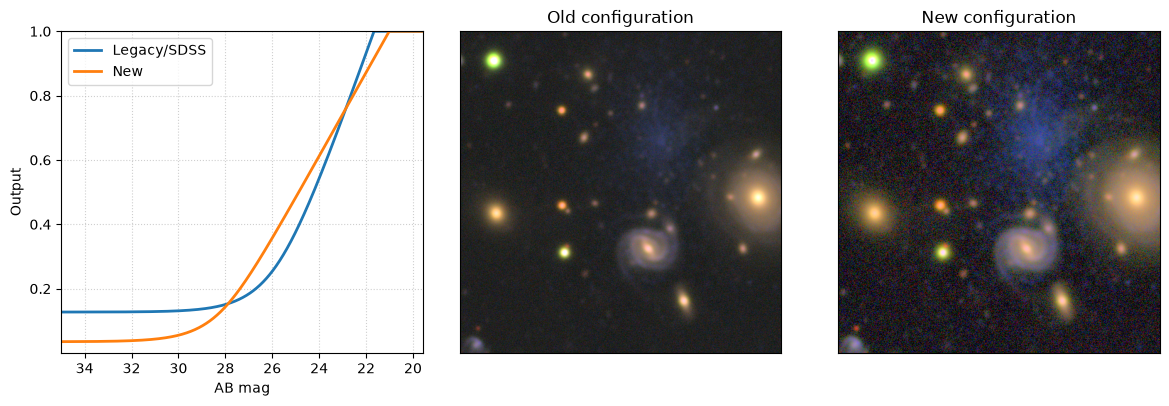

In [5]:
### Plotting below...

plt.figure(figsize = (12,4))

plt.subplot(1,3,1)

plot_curve(asinh, Q = Q, stretch = stretch, m = offset, label = 'Legacy/SDSS', ax = plt.gca()) #In the asinh parameterization, m acts as the offset...
plot_curve(asinh, Q = Q_new, stretch = stretch_new, m = offset_new, label = 'New', ax = plt.gca())
plt.legend()


plt.subplot(1,3,2)
rgb = make_image(imgs, bands, weights, func = asinh, Q = Q, stretch = stretch, offset = offset)
plot_image(rgb, ax = plt.gca())
plt.title('Old configuration')

plt.subplot(1,3,3)

rgb = make_image(imgs, bands, weights_new, func = asinh, Q = Q_new, stretch = stretch_new, offset = offset_new)
plot_image(rgb, ax = plt.gca())
plt.title('New configuration')


plt.tight_layout()
plt.show()

With this new setup, I've lowered the noise floor a bit (using offset), boosted faint magnitudes between ~27-23 mag (using stretch), and pushed the saturation magnitudes a bit higher (using Q). As a result, the fainter structures should pop a bit more, and bright cores should be a bit less saturated.

### Part 3: Test with more images

Let's now try out the new configuration parameters on a few more images. 

In [6]:
# Preload all images you want to test here

images_dir = '../data/Rubin/'
names = ['example1.fits','example2.fits','example3.fits','example4.fits','example5.fits','example6.fits','example7.fits','example8.fits','example9.fits','example10.fits']
filelocs = [f'{images_dir}/{name}' for name in names]


preloaded_imgs = []
for fileloc in filelocs:
    with fits.open(fileloc) as hdul:
        g = njy_to_nanomaggy(hdul[1].data)
        r = njy_to_nanomaggy(hdul[2].data)
        i = njy_to_nanomaggy(hdul[3].data)
        preloaded_imgs.append([g, r, i])

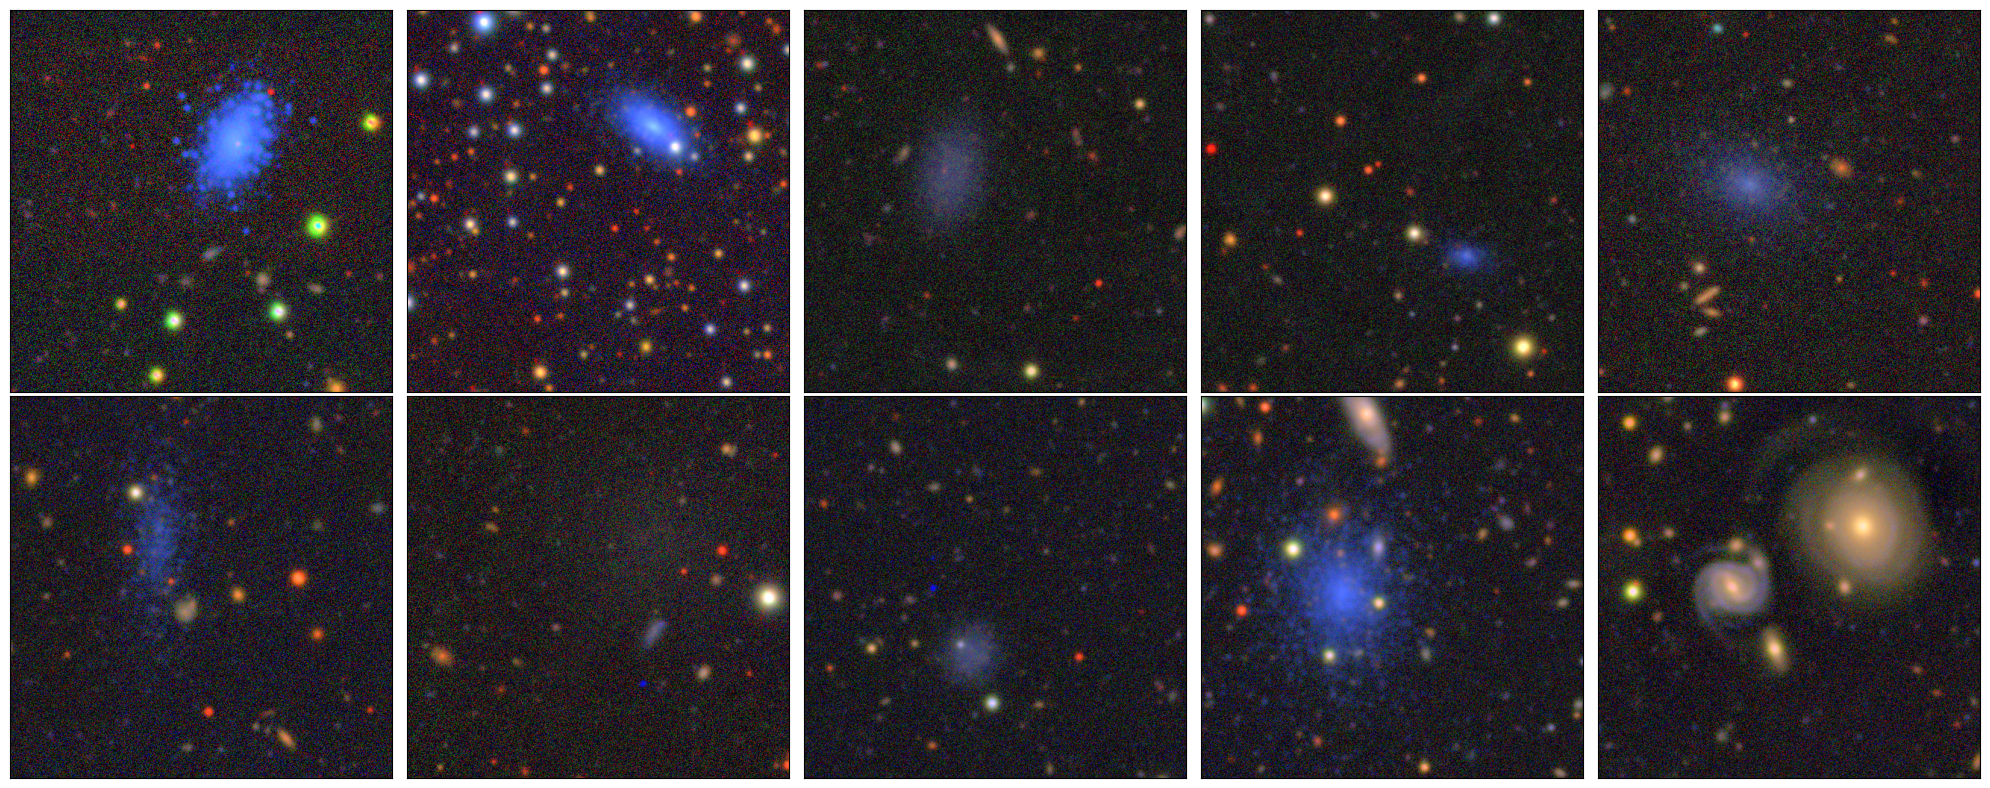

In [7]:
# And plotting here...

nfigs = len(preloaded_imgs)
ncols = 5
nrows = math.ceil(nfigs/ncols)

plt.figure(figsize = (ncols*4,nrows*4))

for ii, img in enumerate(preloaded_imgs):

    plt.subplot(nrows,ncols,ii+1)

    rgb = make_image(img, bands, weights_new, func = asinh, Q = Q_new, stretch = stretch_new, offset = offset_new)
    plot_image(rgb, ax = plt.gca())

plt.tight_layout()
plt.show()